# Part 1(b): DCGAN on CIFAR-10

This notebook presents the final results for a **wider unconditional DCGAN** trained on **CIFAR-10** for **30 epochs on a Tesla T4 GPU**.

The main body covers the final model behaviour, stored outputs and their interpretation. The full implementation is in the appendix.


## 1.1 Q1b(i): Model Construction and Training Setup

### Implemented model (direct statement)
For Q1b(i), the implemented final model is an **unconditional DCGAN-style GAN** for CIFAR-10, trained for 30 epochs on a Tesla T4 GPU. The generator maps a 100-dimensional latent vector to a $3 \times 32 \times 32$ RGB image, while the discriminator maps a $3 \times 32 \times 32$ RGB image to a scalar realism logit.

### Data and preprocessing
- Dataset: CIFAR-10 training split (RGB colour images, $32 \times 32$).
- Preprocessing used in training:
  - `RandomHorizontalFlip()`
  - `ToTensor()`
  - `Normalize((0.5,0.5,0.5), (0.5,0.5,0.5))`
- Reason: this maps real images to approximately $[-1,1]$, matching the generator output range from `tanh`. For display, generated and reference images are denormalised back to $[0,1]$.
- Horizontal flips are valid augmentations for CIFAR-10 and broaden effective distributional coverage at very low computational cost.

### Transformation maps
The generator is the learned transformation
$$
G_\theta: \mathbb{R}^{100} \to \mathbb{R}^{3 \times 32 \times 32},
$$
with channel progression $100 \to 512 \to 256 \to 128 \to 3$ and spatial progression $1\times1 \to 4\times4 \to 8\times8 \to 16\times16 \to 32\times32$.

The discriminator is the reverse map
$$
D_\phi: \mathbb{R}^{3 \times 32 \times 32} \to \mathbb{R},
$$
with channel progression $3 \to 64 \to 128 \to 256 \to 1$ and spatial progression $32\times32 \to 16\times16 \to 8\times8 \to 4\times4 \to 1\times1$.

The discriminator output is a scalar realism score (logit), not a probability.

Early short CPU runs are used only as background motivation: they showed that the narrower generator could learn colour and rough structure, but plateaued relatively early. The wider generator delayed that plateau and improved visual structure in later epochs, indicating that generator-side capacity was a key bottleneck.

### Training objective and update scheme
The standard GAN minimax game is:
$$
\min_{\theta} \max_{\phi} \; V(D_\phi, G_\theta)
= \mathbb{E}_{x \sim p_{\text{data}}}[\log D_\phi(x)]
+ \mathbb{E}_{z \sim p_z}[\log(1 - D_\phi(G_\theta(z)))].
$$

In practice, the implemented generator update uses the non-saturating form:
$$
\min_{\theta} \; \mathcal{L}_G^{\text{NS}}
= -\mathbb{E}_{z \sim p_z}[\log D_\phi(G_\theta(z))].
$$

This BCE-style adversarial framework is the core formulation used for the final DCGAN model in Q1b(i). Later private follow-up experiments tested alternative objectives (notably LSGAN) to assess whether smoother gradients improved adversarial balance.

### Sample Generation Procedure
To generate samples, a latent vector $z$ is drawn from $\mathcal{N}(0, I^{100})$ and passed through $G_\theta$ to produce a synthetic RGB image. The generator outputs values in $[-1,1]$ because of the final `tanh` layer, then outputs are denormalised to $[0,1]$ for visualisation. This is the procedure used to produce the generated grids shown below.


### 1.1.6 DCGAN architecture schematic (conceptual support)
The model follows the DCGAN architecture of Radford, Metz and Chintala (2015), [*Unsupervised Representation Learning with Deep Convolutional GANs*](https://arxiv.org/abs/1511.06434). The implemented channel progression is:

- **Generator channels:** $100 \to 512 \to 256 \to 128 \to 3$, spatially $1\times1 \to 4\times4 \to 8\times8 \to 16\times16 \to 32\times32$
- **Discriminator channels:** $3 \to 64 \to 128 \to 256 \to 1$, spatially $32\times32 \to 16\times16 \to 8\times8 \to 4\times4 \to 1\times1$

The final model intentionally uses an asymmetric design: a wider Generator ($100 \to 512 \to 256 \to 128 \to 3$, 3,448,576 parameters) paired with a narrower Discriminator ($3 \to 64 \to 128 \to 256 \to 1$, 663,296 parameters), prioritising generator-side capacity.


## 1.2 Reference CIFAR-10 Samples

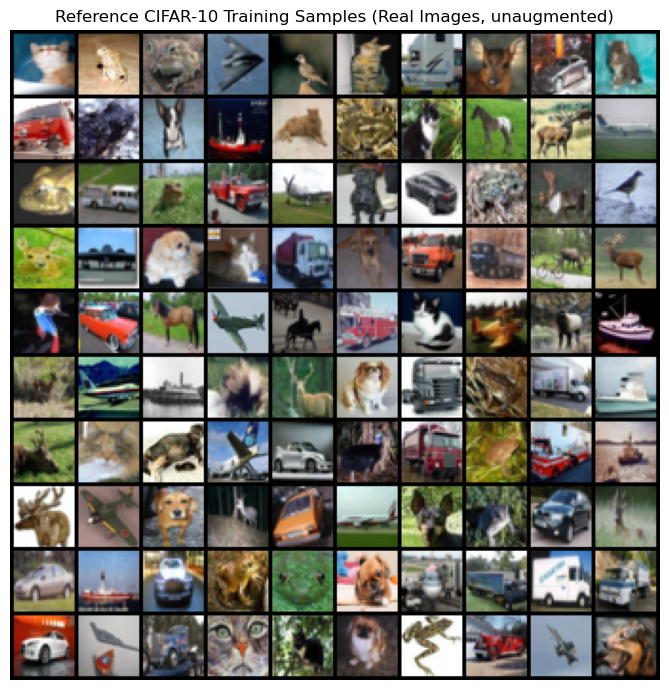

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

base_dir = Path('experimentations')

fig, ax = plt.subplots(1, 1, figsize=(7, 7))
ref_img = mpimg.imread(base_dir / 'real_reference_clean.png')
ax.imshow(ref_img)
ax.set_title('Reference CIFAR-10 Training Samples (Real Images, unaugmented)', fontsize=12)
ax.axis('off')
plt.tight_layout()
plt.show()

The reference grid shows the colour range, texture variability, and structural diversity that the generator is trying to learn from CIFAR-10. In the qualitative analysis, generated outputs are compared directly against this reference: they recover broad colour statistics and rough object structure, but remain blurrier and less semantically consistent than real images.


## Training Results Summary

The table below summarises the per-epoch training metrics across all 30 epochs. D Loss and G Loss are BCEWithLogits values. D(real) and D(fake) are mean sigmoid discriminator outputs on real and generated images respectively, tracking adversarial confidence throughout training.
D Loss and G Loss are raw `BCEWithLogitsLoss` values computed on discriminator logits, whereas D(real) and D(fake) are mean post-sigmoid discriminator outputs included for interpretability only.


In [4]:
import pandas as pd
from pathlib import Path

base_dir = Path('experimentations')
results_df = pd.read_csv(base_dir / 'results.csv')
results_df = results_df.rename(columns={
    'Epoch': 'Epoch',
    'D_loss': 'D Loss',
    'G_loss': 'G Loss',
    'D_real': 'D(real)',
    'D_fake': 'D(fake)',
    'Epoch_time_sec': 'Time (s)'
})
results_df['Time (s)'] = results_df['Time (s)'].round(1)
results_df[['D Loss', 'G Loss', 'D(real)', 'D(fake)']] = results_df[['D Loss', 'G Loss', 'D(real)', 'D(fake)']].round(4)
results_df.set_index('Epoch', inplace=True)
results_df

,D Loss,G Loss,D(real),D(fake),Time (s)
Epoch,,,,,
1,0.8304,3.4013,0.6953,0.2015,45.8
2,0.8824,2.3290,0.6637,0.2321,46.6
3,0.8195,2.3504,0.6878,0.2087,47.5
4,0.9515,1.8824,0.6340,0.2638,47.8
5,0.9687,1.8128,0.6240,0.2744,47.9
6,0.9160,1.8402,0.6452,0.2536,47.7
7,0.9613,1.7372,0.6277,0.2713,47.7
8,0.9549,1.6819,0.6280,0.2710,47.7
9,0.9830,1.6023,0.6177,0.2812,47.8


## 1.3 Training Loss and Confidence Plots (30 epochs)

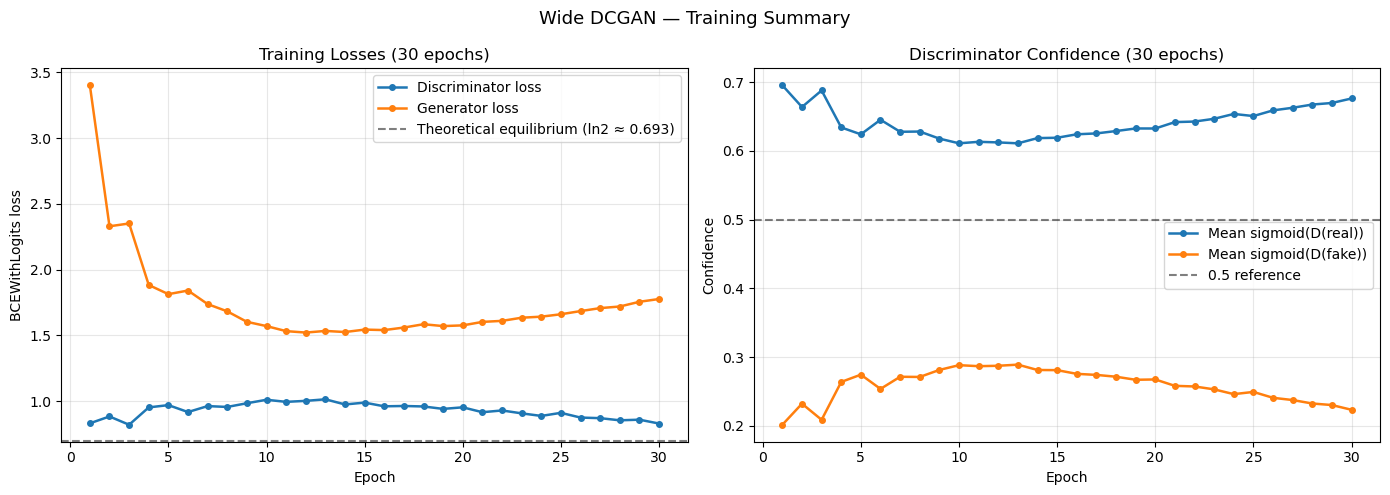

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

base_dir = Path('experimentations')
results_df = pd.read_csv(base_dir / 'results.csv')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(results_df["Epoch"], results_df["D_loss"],
             marker="o", linewidth=1.8, markersize=4, label="Discriminator loss")
axes[0].plot(results_df["Epoch"], results_df["G_loss"],
             marker="o", linewidth=1.8, markersize=4, label="Generator loss")
axes[0].axhline(0.693, linestyle="--", color="black",
                alpha=0.5, label="Theoretical equilibrium (ln2 ~ 0.693)")
axes[0].set_title("Training Losses (30 epochs)")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("BCEWithLogits loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(results_df["Epoch"], results_df["D_real"],
             marker="o", linewidth=1.8, markersize=4, label="Mean sigmoid(D(real))")
axes[1].plot(results_df["Epoch"], results_df["D_fake"],
             marker="o", linewidth=1.8, markersize=4, label="Mean sigmoid(D(fake))")
axes[1].axhline(0.5, linestyle="--", color="black", alpha=0.5, label="0.5 reference")
axes[1].set_title("Discriminator Confidence (30 epochs)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Confidence")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.suptitle("Wide DCGAN — Training Summary", fontsize=13)
plt.tight_layout()
plt.show()

## 1.4 Interpretation of Quantitative Results (Q1b(i))

The 30-epoch wider DCGAN run is the main evidence base for Q1b(i). It shows a clear two-stage pattern.

**Stage 1 (roughly epochs 1-12):** Generator loss falls sharply (3.40 to about 1.52), while $D(\text{real})$ decreases and $D(\text{fake})$ increases. This indicates productive adversarial learning: generated samples become harder for the discriminator to reject.

**Stage 2 (later epochs):** Improvement becomes more limited. Generator loss rises again toward 1.78, while $D(\text{real})$ rises and $D(\text{fake})$ falls, showing discriminator recovery. This is characteristic GAN oscillation and indicates diminishing returns from longer training under the same baseline setup.

The key point is that GANs are not expected to behave like supervised learning, where losses should decrease monotonically. What matters is whether generator and discriminator remain in a productive adversarial balance, and whether image quality improves alongside stable, interpretable dynamics. In this run, early and middle phases improve strongly, but later epochs show that simply adding more training time is not the main solution.


## 1.5 Generated Image Grids — Progression and Final Output

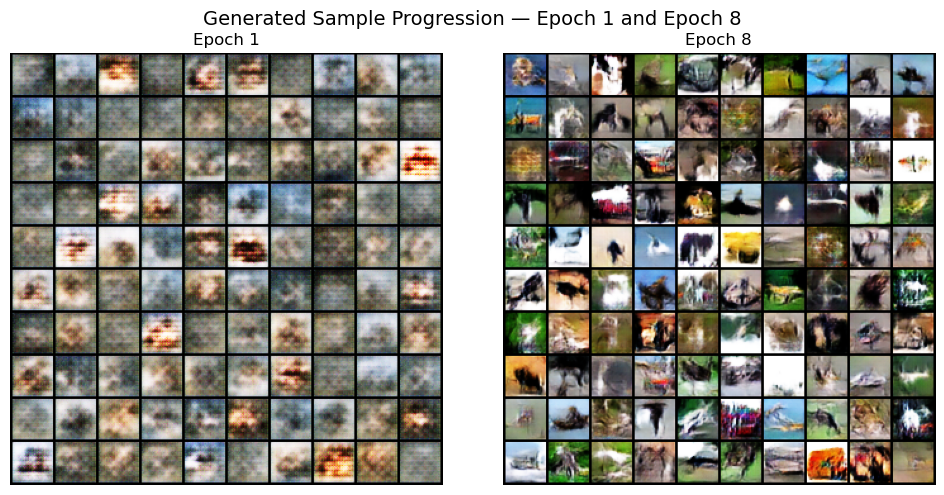

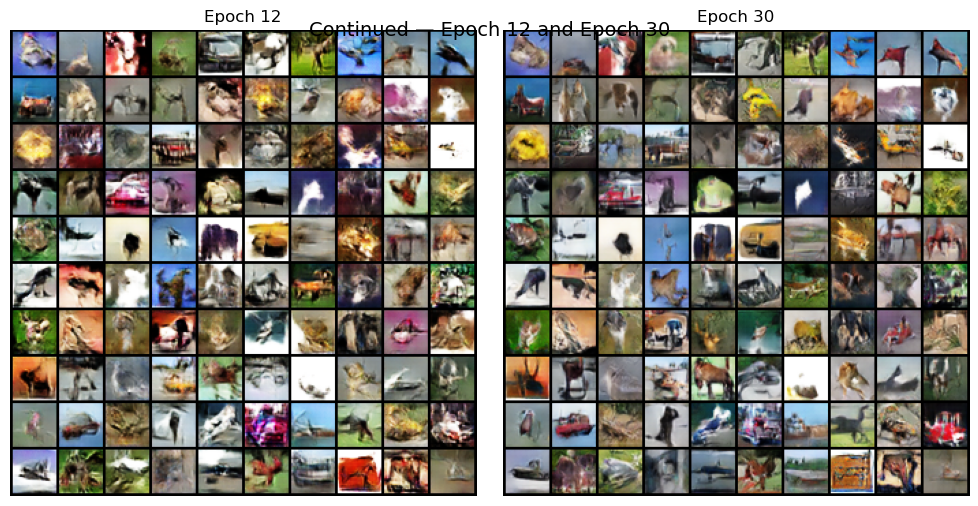

In [7]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from pathlib import Path

base_dir = Path('experimentations')

# Progression grids - row 1
epochs_row1 = [1, 8]
fig, axes = plt.subplots(1, len(epochs_row1), figsize=(10, 5))
for ax, ep in zip(axes, epochs_row1):
    img = mpimg.imread(base_dir / f'epoch{ep:02d}_grid.png')
    ax.imshow(img)
    ax.set_title(f'Epoch {ep}')
    ax.axis('off')
plt.suptitle('Generated Sample Progression — Epoch 1 and Epoch 8', fontsize=14)
plt.tight_layout()
plt.show()

# Progression grids - row 2
epochs_row2 = [12, 30]
fig2, axes2 = plt.subplots(1, len(epochs_row2), figsize=(10, 5))
for ax, ep in zip(axes2, epochs_row2):
    img = mpimg.imread(base_dir / f'epoch{ep:02d}_grid.png')
    ax.imshow(img)
    ax.set_title(f'Epoch {ep}')
    ax.axis('off')
plt.tight_layout()
plt.suptitle('Continued — Epoch 12 and Epoch 30', fontsize=14)
plt.show()


## 1.6 Interpretation of Qualitative Results (Q1b(i))

The progression grids show substantial qualitative improvement over training.

**Epoch 1:** Outputs are mostly incoherent colour patches with little recognisable structure.

**Epoch 8:** Colour groupings are more coherent and rough object-like forms begin to emerge.

**Epoch 12:** Structure is clearer in many cells, with recognisable foreground/background layouts.

**Later phase (towards epoch 30):** The wider DCGAN produces recognisable object-like structure and coherent colour organisation, but gains become increasingly marginal. Fine detail and semantic sharpness remain limited.

Compared with the real reference grid, generated images capture broad colour and shape statistics, but still look blurrier and less class-consistent. This supports the quantitative result: the model improves meaningfully, yet late-stage refinement is constrained by the adversarial setup rather than by epoch count alone.


## 1.7 Q1b(ii): How the GAN Procedure Can Be Improved

This section is Q1b(ii): recommendations grounded in observed behaviour from the main 30-epoch wider DCGAN run plus follow-up experiments.

### Model improvements
The original narrower generator ($100 \to 256 \to 128 \to 64 \to 3$) showed a representational bottleneck. Widening to $100 \to 512 \to 256 \to 128 \to 3$ increased capacity and delayed plateau, with stronger structural development in generated images. This is direct evidence that generator capacity was a primary limiting factor. Next model-side steps are spectral normalisation (to constrain discriminator sharpness) and class-conditional GANs (to separate class-specific structure more cleanly).

### Data improvements
The initial baseline did not use augmentation. Later GPU runs introduced `RandomHorizontalFlip()`, which improved effective coverage and robustness. A half-dataset branch showed that longer training on reduced data coverage did not recover image quality, indicating that data diversity and full-distribution exposure matter at least as much as raw epoch count.

### Loss-function improvements
BCE-style training in the baseline improved early but plateaued into a less favourable late regime with discriminator recovery. A private LSGAN branch (least-squares adversarial objective) produced smoother, more balanced dynamics with a narrower real/fake gap than the BCE baseline, indicating better generator gradient quality. A later continuation with one-sided smoothing (real targets 0.9) further supported this direction, though it was introduced mid-run and is therefore a secondary comparison.


A concrete LSGAN GPU run (15 epochs, Tesla T4, same baseline architecture, `MSELoss` replacing `BCEWithLogitsLoss`) supports this: G loss converged to about 0.54 by epoch 3 and remained stable, whereas BCE later plateaued/rose to about 1.78 by epoch 30. Likewise, D(fake) stabilised around 0.36 under LSGAN, compared with a fall to about 0.22 under BCE, indicating a healthier generator-discriminator equilibrium.

Representative LSGAN values:
- Epoch 1: D loss 0.4709, G loss 2.4114, D(real) 0.8464, D(fake) 0.1634
- Epoch 5: D loss 0.3938, G loss 0.6035, D(real) 0.6327, D(fake) 0.3621
- Epoch 10: D loss 0.3940, G loss 0.5378, D(real) 0.6232, D(fake) 0.3758
- Epoch 15: D loss 0.3677, G loss 0.5411, D(real) 0.6392, D(fake) 0.3606

Based on performed experiments, the evidence-based priority is:
1. LSGAN (strongest direct support)
2. Wider generator / capacity adjustments
3. Data diversity improvements (augmentation + full coverage)
4. Heavier future extensions: spectral normalisation, class-conditional GAN, WGAN-GP

So WGAN-GP remains plausible, but it is no longer the first recommendation given the stronger empirical support for LSGAN and capacity changes.


## 1.8 Conclusion

The wider 30-epoch DCGAN baseline successfully learned meaningful colour structure and recognisable object-like forms from CIFAR-10. Improvements were substantial in the early and middle phases of training.

Later epochs showed diminishing returns and discriminator recovery, so longer training alone was not the main solution. Follow-up GPU experiments indicated that changing the adversarial objective (especially LSGAN) and strengthening generator capacity produced more meaningful gains than simply extending baseline BCE training.

The final recommendations are therefore evidence-based: prioritise smoother adversarial objectives, maintain adequate generator capacity, and preserve data diversity/coverage, with spectral normalisation, regularisation, and class-conditioning as the next practical extensions.


## 1.9 Appendix: Wider DCGAN Implementation

The cells below contain the complete cleaned implementation of the wider DCGAN used to produce all Q1b(i) results. This code was run on a Tesla T4 GPU via Google Colab. Running it writes the per-epoch image grids to an `experimentations/` folder, which the results cells above read from. That folder (and the earlier trial runs) is not included in this repository, so the outputs above are the stored results of the original run.

In [ ]:
import os
import random
import time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, utils
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

In [ ]:
LATENT_DIM   = 100
IMG_CHANNELS = 3
BATCH_SIZE   = 64
NUM_EPOCHS   = 30
LR_G         = 2e-4   # Two Timescale Update Rule (TTUR, Heusel et al. 2017): asymmetric learning rates reduce discriminator dominance
LR_D         = 1e-4   # Two Timescale Update Rule (TTUR, Heusel et al. 2017): asymmetric learning rates reduce discriminator dominance
BETAS        = (0.5, 0.999)
NUM_WORKERS  = 2

save_dir = Path("experimentations")
save_dir.mkdir(exist_ok=True)

In [ ]:
transform = transforms.Compose([
    transforms.RandomHorizontalFlip(),   # doubles effective distribution coverage
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=True,
)
print(f"Dataset size: {len(train_dataset)} | Batches per epoch: {len(train_loader)}")

In [ ]:
class Generator(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.net = nn.Sequential(
            # (B,100,1,1) -> (B,512,4,4)
            nn.ConvTranspose2d(latent_dim, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            # (B,512,4,4) -> (B,256,8,8)
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # (B,256,8,8) -> (B,128,16,16)
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # (B,128,16,16) -> (B,3,32,32)
            nn.ConvTranspose2d(128, IMG_CHANNELS, 4, 2, 1, bias=False),
            nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z)

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            # (B,3,32,32) -> (B,64,16,16)
            nn.Conv2d(IMG_CHANNELS, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # (B,64,16,16) -> (B,128,8,8)
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # (B,128,8,8) -> (B,256,4,4)
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
        )
        self.classifier = nn.Conv2d(256, 1, 4, 1, 0, bias=False)

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x.view(-1, 1)


In [ ]:
def weights_init(m):
    classname = m.__class__.__name__
    if classname.find("Conv") != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find("BatchNorm") != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

G = Generator().to(device)
D = Discriminator().to(device)
G.apply(weights_init)
D.apply(weights_init)

print(f"Generator parameters:     {sum(p.numel() for p in G.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in D.parameters()):,}")

criterion   = nn.BCEWithLogitsLoss()
optimizer_G = optim.Adam(G.parameters(), lr=LR_G, betas=BETAS)
optimizer_D = optim.Adam(D.parameters(), lr=LR_D, betas=BETAS)

fixed_noise = torch.randn(100, LATENT_DIM, 1, 1, device=device)

In [ ]:
def save_generated_grid(generator, noise, filename, nrow=10):
    generator.eval()
    with torch.no_grad():
        fake = generator(noise).detach().cpu()
    generator.train()
    fake = (fake + 1) / 2
    fake = torch.clamp(fake, 0, 1)
    utils.save_image(fake, filename, nrow=nrow)

history = {"d_loss": [], "g_loss": [], "d_real": [], "d_fake": [], "epoch_time_sec": []}

for epoch in range(NUM_EPOCHS):
    epoch_start = time.time()
    running_d_loss = running_g_loss = 0.0
    running_d_real = running_d_fake = 0.0
    num_batches = len(train_loader)

    for real_imgs, _ in train_loader:
        real_imgs = real_imgs.to(device, non_blocking=True)
        bsz = real_imgs.size(0)

        real_targets = torch.full((bsz, 1), 0.9, device=device)  # label smoothing
        fake_targets = torch.zeros((bsz, 1), device=device)

        # Train D
        optimizer_D.zero_grad(set_to_none=True)
        z           = torch.randn(bsz, LATENT_DIM, 1, 1, device=device)
        fake_imgs   = G(z)
        real_logits = D(real_imgs)
        fake_logits = D(fake_imgs.detach())
        d_loss      = criterion(real_logits, real_targets) + criterion(fake_logits, fake_targets)
        d_loss.backward()
        optimizer_D.step()

        # Train G
        optimizer_G.zero_grad(set_to_none=True)
        z                 = torch.randn(bsz, LATENT_DIM, 1, 1, device=device)
        fake_imgs         = G(z)
        fake_logits_for_g = D(fake_imgs)
        g_loss            = criterion(fake_logits_for_g, real_targets)
        g_loss.backward()
        optimizer_G.step()

        running_d_loss += d_loss.item()
        running_g_loss += g_loss.item()
        running_d_real += torch.sigmoid(real_logits).mean().item()
        running_d_fake += torch.sigmoid(fake_logits).mean().item()

    epoch_time = time.time() - epoch_start
    avg_d  = running_d_loss / num_batches
    avg_g  = running_g_loss / num_batches
    avg_dr = running_d_real / num_batches
    avg_df = running_d_fake / num_batches

    history["d_loss"].append(avg_d)
    history["g_loss"].append(avg_g)
    history["d_real"].append(avg_dr)
    history["d_fake"].append(avg_df)
    history["epoch_time_sec"].append(epoch_time)

    print(f"Epoch [{epoch+1:2d}/{NUM_EPOCHS}] D={avg_d:.4f} G={avg_g:.4f} "
          f"D(real)={avg_dr:.4f} D(fake)={avg_df:.4f} time={epoch_time:.1f}s")

    save_generated_grid(G, fixed_noise, save_dir / f"epoch{epoch+1:02d}_grid.png")

print("Training complete.")